# Two conditions: where spatial organization changes

This tutorial tests which genes differ in spatial organization between amyloid-positive and amyloid-negative mouse brain sections.

- The Trem2/5xFAD MERFISH dataset contains 19 sections: 10 `amyloid+` and 9 `amyloid-`, with 300 genes measured per cell.
- Input: `~/spectrast_data/trem2_5xfad.h5ad`, created by `00b_preprocess_trem2.ipynb`.
- For each gene, we measure spatial organization across neighborhood radii on a shared lattice, then compare the average curves between groups.
- The test statistic, `T_max`, is the largest difference across radii after scaling by its null variability.
- We shuffle whole-section labels, not individual cells. A significant result indicates a difference in spatial organization, but does not explain its cause.
- Arm A is `amyloid+`; arm B is `amyloid-`. All signed differences are `amyloid+ minus amyloid-`.

## 1. Load the cohort and split it into sections

Spatial statistics are computed per section (cells from two slides share no coordinate frame), so the
cohort is split into one view per section and the views are grouped by arm. `set_backend("auto")`
uses the GPU when one is available; both arms are always computed on the same backend.

In [1]:
import os, time
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
import spectrast
from spectrast import diff, gr, pl

print("backend:", spectrast.set_backend("auto"))
full = sc.read_h5ad(os.path.expanduser("~/spectrast_data/trem2_5xfad.h5ad"))
genes = list(full.var_names)

views, section_names = diff.split_sections(full, "section_id")      # one view per section, no copies
A, B = diff.groups_from_obs(views, "amyloid", ["amyloid+"], ["amyloid-"])
print(f"{full.n_obs:,} cells x {full.n_vars} genes; {len(A)} amyloid+ (A) and {len(B)} amyloid- (B) sections")

backend: mps


420,563 cells x 300 genes; 10 amyloid+ (A) and 9 amyloid- (B) sections


## 2. Test four statistics on all 300 genes

We test four statistics, each a different question about the same gene:

* **Moran's I**: do neighbouring cells share values (clustering)?
* **Geary's C**, reported as **1 − C** so that it, too, rises with clustering; it weights sharp
  differences between neighbours more than Moran's I does.
* **LOSH concentration**: how unevenly local variability is spread over the tissue (the Gini
  coefficient of the local heteroscedasticity map).
* **Focality**: whether the local clustering is spread out or concentrated in a few places (the Gini
  coefficient of the local Moran map).



In [2]:
print(diff.design_floor(len(A), len(B), n_features=len(genes)))

AXES = ("moran", "geary", "losh", "focality")
res, timing = {}, {}
for axis in AXES:
    t0 = time.perf_counter()
    res[axis] = diff.differential_cohort(
        full, "amyloid", ["amyloid+"], ["amyloid-"], sample_key="section_id",
        axis=axis, features=genes, null="replicate", n_perm=2000, seed=0, return_curves=True)
    timing[axis] = time.perf_counter() - t0
summary = pd.DataFrame({"called (FDR < 0.05)": {a: int((res[a][0].fdr < 0.05).sum()) for a in AXES},
                        "smallest p": {a: res[a][0].p.min() for a in AXES},
                        "seconds": {a: round(timing[a], 1) for a in AXES}})
summary

{'kind': 'unpaired', 'n_partitions': 92378, 'p_floor': 1.082508822446903e-05, 'alpha': 0.05, 'n_features': 300, 'fdr_reachable': True}


<ipython-input>:7: UserWarning: 16 of 300 features (5%) have a characteristic length in one arm but not the other, so delta_scale_um is NaN for them. That is the reduction declining, not a failure: an arm whose organization curve never falls to its own mid-range has no length to difference. p, FDR and T_max are unaffected — they do not use this column. Inspect the per-arm curves before treating these as missing data, and use reduction='centroid' only if you need the pre-2026-08-18 numbers.
  res[axis] = diff.differential_cohort(


<ipython-input>:7: UserWarning: 24 of 300 features (8%) have a characteristic length in one arm but not the other, so delta_scale_um is NaN for them. That is the reduction declining, not a failure: an arm whose organization curve never falls to its own mid-range has no length to difference. p, FDR and T_max are unaffected — they do not use this column. Inspect the per-arm curves before treating these as missing data, and use reduction='centroid' only if you need the pre-2026-08-18 numbers.
  res[axis] = diff.differential_cohort(


<ipython-input>:7: UserWarning: 22 of 300 features (7%) have a characteristic length in one arm but not the other, so delta_scale_um is NaN for them. That is the reduction declining, not a failure: an arm whose organization curve never falls to its own mid-range has no length to difference. p, FDR and T_max are unaffected — they do not use this column. Inspect the per-arm curves before treating these as missing data, and use reduction='centroid' only if you need the pre-2026-08-18 numbers.
  res[axis] = diff.differential_cohort(


,called (FDR < 0.05),smallest p,seconds
moran,9,0.0005,33.4
geary,9,0.0005,49.1
losh,6,0.0005,170.0
focality,13,0.0005,40.1


Each entry of `res` is a `(table, curves)` pair. The table has one row per gene; the curves dict
holds what the test was computed from (per-section curves, arm means, the null spread at every
radius), which the plots below read. The radii and the lattice were derived from the sections' own
cell spacing and are shared by every section and every statistic:

In [3]:
mor, cm = res["moran"]
r = cm["radii_um"]
print(f"{len(r)} radii from {r[0]:.0f} to {r[-1]:.0f} µm; lattice bin {cm['bin_size']:.1f} µm")

18 radii from 31 to 1226 µm; lattice bin 15.3 µm


The Moran's I calls. `dI_at_max` is the change at the tested radius `r_at_max_um`, and
`n_radii_exceeded` counts the radii (of all those swept) where the difference leaves the simultaneous
envelope:

In [4]:
cols = ["gene", "dI_at_max", "T_max", "r_at_max_um", "n_radii_exceeded", "p", "fdr", "delta_scale_um"]
mor[mor.fdr < 0.05].sort_values(["fdr", "T_max"], ascending=[True, False])[cols].round(4)

,gene,dI_at_max,T_max,r_at_max_um,n_radii_exceeded,p,fdr,delta_scale_um
72,Ctss,0.1269,4.0873,30.6515,18,0.0005,0.0167,NaN
149,Inpp5d,0.0800,4.0525,30.6515,18,0.0005,0.0167,NaN
285,Trem2,0.0795,4.0283,76.6287,18,0.0005,0.0167,NaN
0,Abi3,0.0326,4.0044,153.2574,18,0.0005,0.0167,NaN
24,C1qa,0.1205,3.9824,30.6515,18,0.0005,0.0167,NaN
66,Csf1r,0.0854,3.9718,45.9772,18,0.0005,0.0167,NaN
266,Spi1,0.0528,3.6968,30.6515,18,0.0005,0.0167,NaN
36,Cbln4,-0.0352,3.4576,291.1892,17,0.0005,0.0167,-96.3776
297,Wfs1,-0.0527,3.3136,245.2119,15,0.0005,0.0167,-7.2803


## 3. Volcano plot

Every gene's signed change in Moran's I at its tested radius (`dI_at_max`, amyloid+ minus amyloid-)
against −log10 FDR; the dashed line is FDR = 0.05. Genes at the permutation floor share one p-value
and therefore one FDR, so they sit on one horizontal line: there the vertical position no longer
ranks them, and the horizontal axis is what separates them. Here all nine Moran's I calls sit at the
floor (p = 1/2,001, FDR 0.017 in the table above), so more permutations would be needed to rank them
by significance.

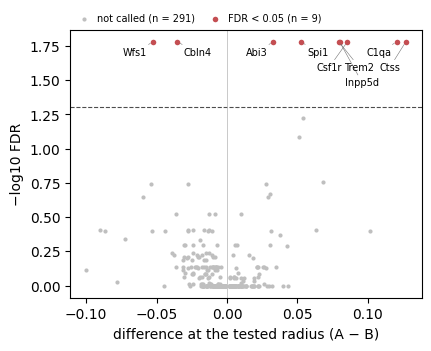

In [5]:
pl.volcano(mor, fdr=0.05, n_label=12);

## 4. One gene's curves: Trem2

The top panel shows the two arm-mean Moran's I curves (bold) over each section's own curve (faint).
The bottom panel is what is tested: the difference between the arm means (amyloid+ minus amyloid-) at
every radius, with the simultaneous envelope shaded. Radii where the difference leaves the envelope
are marked; a gene is significant when it leaves the envelope somewhere. For Trem2 the difference leaves the envelope at every radius swept, so this is a change over the whole range, not at one scale.

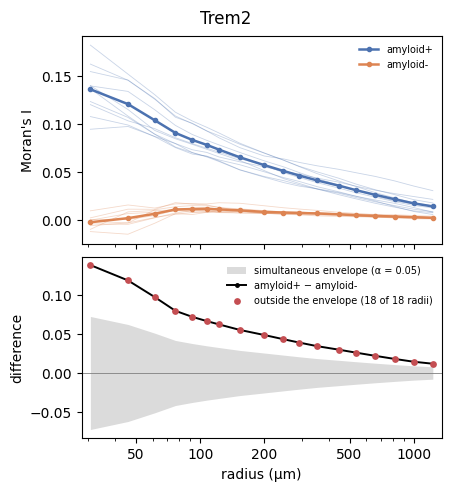

In [6]:
pl.diff_curves(cm, "Trem2", show_units=True);

The same per-section curves, on their own. These are the replicates the null relabels, so the spread
of each arm's sections against the gap between the arms is, informally, what the test weighs.

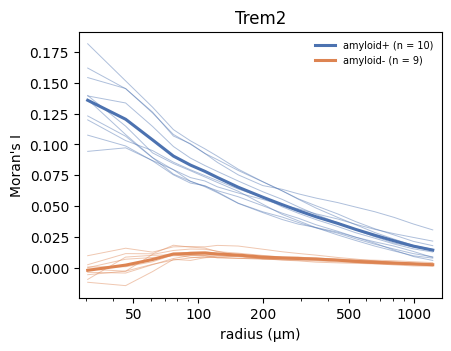

In [7]:
pl.unit_curves(cm, "Trem2");

## 5. Does the characteristic scale move?

The effect plane puts the tested change (`dI_at_max`, x) against the shift in characteristic scale
(`delta_scale_um`, y): the radius at which each arm's mean curve falls to half its own range, amyloid+
minus amyloid-. Hollow markers are shifts no larger than the two arms' section-to-section spread in
scale. Genes with no defined shift are kept in the band at the bottom rather than dropped.

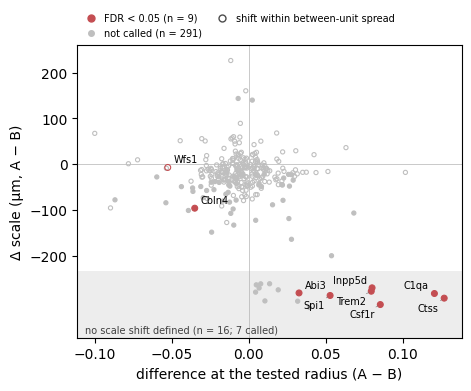

In [8]:
pl.effect_plane(mor, fdr=0.05, n_label=12);

In [9]:
hit = mor[mor.fdr < 0.05].gene.tolist()
i = [cm["ids"].index(g) for g in hit]
mA, mB = cm["meanA"][:, i], cm["meanB"][:, i]
pd.DataFrame({"scale amyloid+ (µm)": cm["scale_meanA_um"][i], "scale amyloid- (µm)": cm["scale_meanB_um"][i],
              "max I amyloid+": mA.max(0), "max I amyloid-": mB.max(0),
              "amyloid- peaks at (µm)": cm["radii_um"][mB.argmax(0)],
              "amyloid- starts below mid-range": mB[0] < (mB.min(0) + mB.max(0)) / 2},
             index=hit).round(3)

,scale amyloid+ (µm),scale amyloid- (µm),max I amyloid+,max I amyloid-,amyloid- peaks at (µm),amyloid- starts below mid-range
Abi3,166.388,NaN,0.071,0.014,91.954,True
C1qa,158.383,NaN,0.120,0.017,76.629,True
Cbln4,164.489,260.866,0.114,0.144,30.651,False
Csf1r,170.329,NaN,0.091,0.017,91.954,True
Ctss,152.010,NaN,0.128,0.014,107.280,True
Inpp5d,155.702,NaN,0.078,0.014,107.280,True
Spi1,192.532,NaN,0.054,0.008,76.629,True
Trem2,116.667,NaN,0.136,0.012,107.280,True
Wfs1,241.759,249.039,0.157,0.247,45.977,False


Seven of the nine significant genes—Abi3, C1qa, Csf1r, Ctss, Inpp5d, Spi1, and Trem2 have no scale-shift estimate because their characteristic scale is undefined in amyloid-. Their spatial clustering is weak in that group (mean Moran’s I below 0.02 at every radius, versus 0.05–0.14 in amyloid+). The curves start below the half-range threshold used to define scale, so there is no scale value to compare. These results reflect stronger clustering, not a measurable shift in length scale. The significance test (p, fdr, T_max) does not use characteristic scale, so the calls remain valid.

## 6. Where in the tissue: neighbourhood maps

For one representative section per arm, each cell is coloured by the average of standardised Trem2 expression over its neighborhood. Expression is standardised within each section, so a change in expression level alone produces no contrast here. The left column uses the tested radius, the right one a radius about three times coarser; each column has one colour scale shared by both arms.

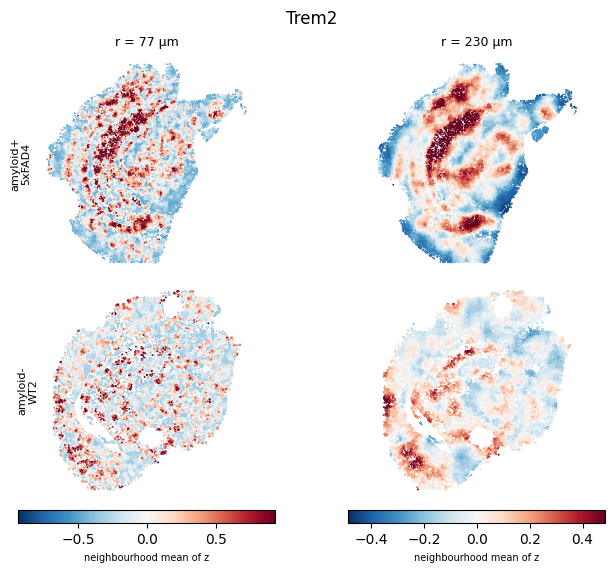

In [10]:
r_test = float(mor.set_index("gene").loc["Trem2", "r_at_max_um"])
pl.neighborhood_maps(A, B, "Trem2", [r_test, 3 * r_test], curves=cm);

## 7. Moran’s I differences across radii

Each row is a significant gene. Red means higher Moran’s I in `amyloid+`; blue means lower. The dot marks the strongest difference after scaling by null variability, not necessarily the largest raw change. Read the row’s colors to see where changes are largest.

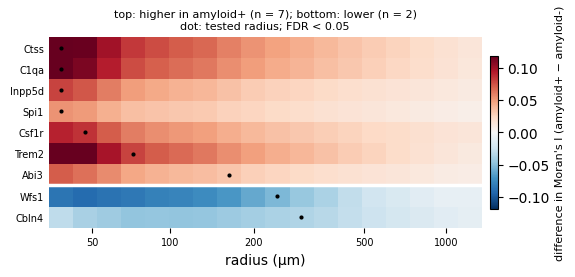

In [11]:
pl.diff_heatmap(cm, df=mor, fdr=0.05);

## 8. Which types of spatial organization change?

Rows show genes significant for at least one statistic. Colors show signed `T_max`: red means more of that pattern in `amyloid+`, blue means less. Squares mark significant results.

FDR is calculated across all 300 genes × 4 statistics, so some results significant in the separate tables may not pass here. Rows are grouped by similarity using Ward clustering.

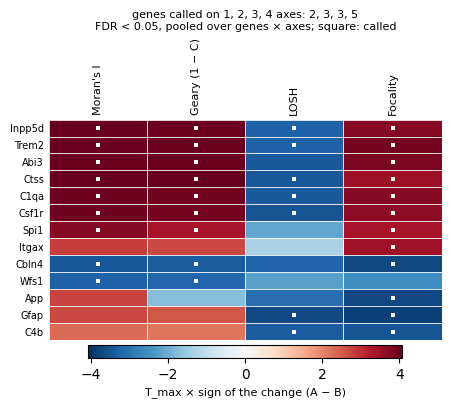

In [12]:
pl.diff_fingerprint(res, fdr=0.05);

In [13]:
q_pooled = diff.bh_fdr(np.concatenate([res[a][0].p.to_numpy() for a in AXES])).reshape(len(AXES), -1)
pd.DataFrame({"called, per-axis FDR": [int((res[a][0].fdr < 0.05).sum()) for a in AXES],
              "called, pooled FDR": [int((q_pooled[k] < 0.05).sum()) for k in range(len(AXES))]},
             index=list(AXES))

,"called, per-axis FDR","called, pooled FDR"
moran,9,9
geary,9,9
losh,6,7
focality,13,12


## 9. Coarser or finer? Scale in each group

Each panel compares characteristic scale in `amyloid-` (x) and `amyloid+` (y). Points above the dashed line indicate coarser patterns in `amyloid+`.

Significant genes are red when the statistic increases and blue when it decreases. Filled points mark scale shifts larger than the between-section spread. Scale is descriptive; significance comes from comparing the full curves. Genes without a scale estimate are omitted and counted in the titles.

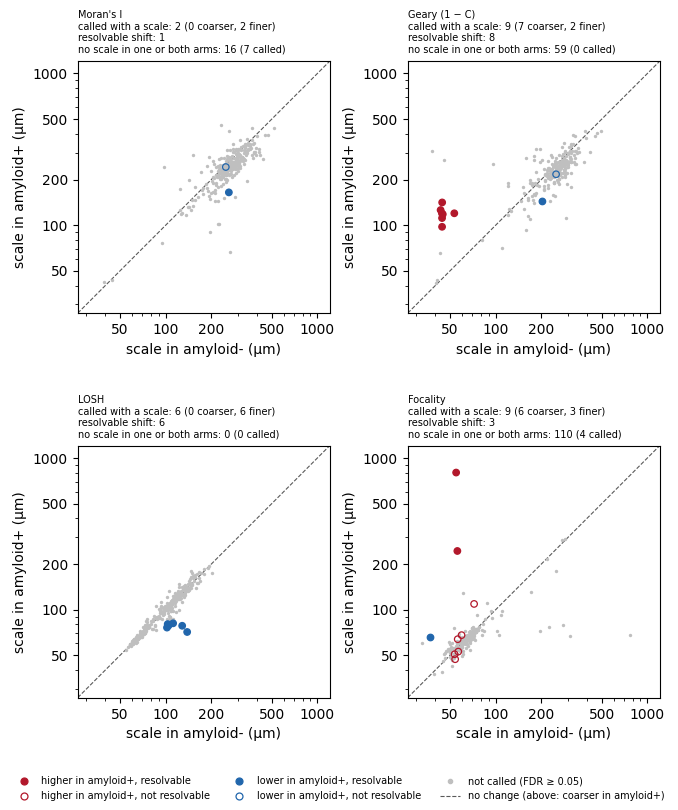

In [14]:
pl.scale_shift(res, fdr=0.05);

## 10. Section by section

`gr.fingerprint_by` measures each gene’s characteristic scale (`scale_um`) separately in each section, using a shared lattice. The plot shows significant Moran’s I genes: one point per section, colored by group, with a black tick marking each gene’s median.

fingerprint_by: 120.7 s for 19 sections


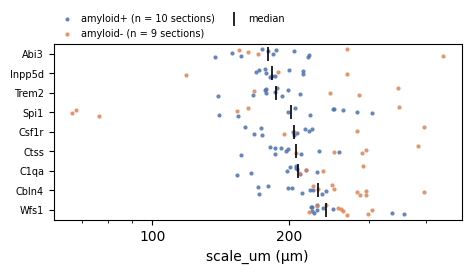

In [15]:
t0 = time.perf_counter()
tidy = gr.fingerprint_by(full, "section_id")
timing["fingerprint_by"] = time.perf_counter() - t0
print(f"fingerprint_by: {timing['fingerprint_by']:.1f} s for {tidy.section_id.nunique()} sections")
arm_of = full.obs.groupby("section_id", observed=True)["amyloid"].first().astype(str)
arm_of = arm_of.sort_values(kind="stable")           # amyloid+ first, so it keeps arm A's colour
called_moran = list(mor.loc[mor.fdr < 0.05, "gene"])
pl.section_scales(tidy, genes=called_moran, groups=arm_of);

For most of the microglial calls, several amyloid- sections have no point: in those sections the
gene has no characteristic scale, the same absence that left seven calls without a scale shift in
section 5. These values are measured section by section, so they need not match the arm-level scales
of section 9, which come from each arm's mean curve.

How reproducible is one section's scale? The pairs view compares two sections of the same genotype,
5xFAD1 and 5xFAD2, over every gene with a scale in both.

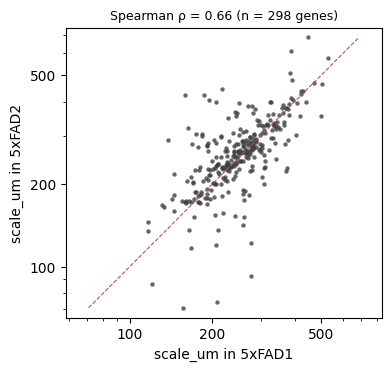

In [16]:
pl.section_scales(tidy, kind="pairs", sections=("5xFAD1", "5xFAD2"));

## Run time

Seconds per step on the machine that built this page. LOSH has no GPU implementation, so it is the
slowest of the four statistics.

In [17]:
t = pd.Series(timing, name="seconds").round(1)
t["total"] = round(sum(timing.values()), 1)
t.to_frame().T

,moran,geary,losh,focality,fingerprint_by,total
seconds,33.4,49.1,170.0,40.1,120.7,413.3
